In [11]:
import pandas as pd

df = pd.read_csv('../data/HHS_Unaccompanied_Alien_Children_Program.csv')
df.shape
df.head()
df.dtypes
df.columns


Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care'],
      dtype='str')

In [12]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
df['Date'].min(), df['Date'].max()

(Timestamp('2023-01-12 00:00:00'), Timestamp('2025-12-21 00:00:00'))

In [13]:
full_range = pd.date_range(df['Date'].min(), df['Date'].max(), freq='D')
missing_dates = full_range.difference(df['Date'])
len(missing_dates), missing_dates

(355,
 DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
                '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
                '2023-01-21', '2023-01-26',
                ...
                '2025-11-22', '2025-11-26', '2025-11-28', '2025-11-29',
                '2025-12-05', '2025-12-06', '2025-12-12', '2025-12-13',
                '2025-12-19', '2025-12-20'],
               dtype='datetime64[us]', length=355, freq=None))

In [14]:
df['Date'].duplicated().sum()

np.int64(449)

In [15]:
df.isna().sum()
df.describe(include='all')

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
count,720,720.000000,720.000000,720.000000,720,720.000000
unique,NaN,NaN,NaN,NaN,642,NaN
top,NaN,NaN,NaN,NaN,"7,546",NaN
freq,NaN,NaN,NaN,NaN,3,NaN
mean,2024-07-06 05:30:00,93.523611,171.494444,128.668056,NaN,173.406944
min,2023-01-12 00:00:00,0.000000,7.000000,0.000000,NaN,0.000000
25%,2023-10-16 18:00:00,12.000000,36.000000,14.000000,NaN,19.750000
50%,2024-07-05 12:00:00,99.000000,193.000000,157.000000,NaN,181.000000
75%,2025-03-25 06:00:00,147.250000,263.250000,199.250000,NaN,267.000000
max,2025-12-21 00:00:00,333.000000,531.000000,440.000000,NaN,505.000000


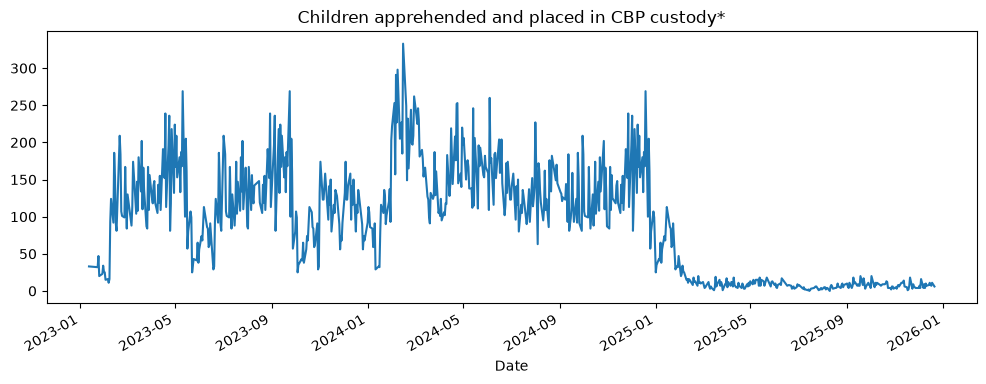

In [16]:
import matplotlib.pyplot as plt

df.set_index('Date')[df.columns[1]].plot(figsize=(12,4))
plt.title(df.columns[1])
plt.savefig('../outputs/figures/sanity_check.png')
plt.show()

In [17]:
dupes = df[df['Date'].duplicated(keep=False)].sort_values('Date')
dupes.head(20)

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
720,NaT,NaN,NaN,NaN,NaN,NaN
721,NaT,NaN,NaN,NaN,NaN,NaN
722,NaT,NaN,NaN,NaN,NaN,NaN
723,NaT,NaN,NaN,NaN,NaN,NaN
724,NaT,NaN,NaN,NaN,NaN,NaN
725,NaT,NaN,NaN,NaN,NaN,NaN
726,NaT,NaN,NaN,NaN,NaN,NaN
727,NaT,NaN,NaN,NaN,NaN,NaN
728,NaT,NaN,NaN,NaN,NaN,NaN
729,NaT,NaN,NaN,NaN,NaN,NaN


In [18]:
df['Children in HHS Care'] = (
    df['Children in HHS Care']
    .astype(str)
    .str.replace(',', '', regex=False)
    .astype(float)
)
df['Children in HHS Care'].describe()

count      720.000000
mean      6061.275000
std       2833.070109
min       1972.000000
25%       2467.750000
50%       6406.500000
75%       8010.250000
max      11516.000000
Name: Children in HHS Care, dtype: float64

In [19]:
# Drop blank trailing rows (NaT dates)
df = df.dropna(subset=['Date']).reset_index(drop=True)
df.shape
df['Date'].duplicated().sum()  # should now be 0

np.int64(0)

In [20]:
df.to_csv('../data/hhs_cleaned.csv', index=False)

## Audit Summary

- **Date range:** 2023-01-12 to 2025-12-21 (720 real daily rows)
- **Missing dates:** 355 days absent — series is not continuous, needs reindexing
- **"Duplicates":** were blank trailing rows (NaT), not real data — dropped
- **Dtype fix:** `Children in HHS Care` converted from text to numeric
- **Status:** data is now clean — ready for reindexing and gap-filling